# Bitcoin OTC: temporal rating accumulation

**Focused question:** How did concentration in accumulated positive ratings compare with concentration in new yearly ratings, and were already highly rated users selected more often than a simple uniform-target baseline predicts? Ratings are directed opinions. The timestamps record when ratings were added; they do not establish that an old rating remained an active relationship.

## 1. Reproduce the outputs

Download the original SNAP file as described in the repository README, then run `python scripts/reproduce.py` from the repository root. The runner includes `temporal_analysis.py` and `temporal_sensitivity.py`. This notebook combines source-based calculations, a small invented example, and the stored full-analysis outputs.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
OUT = ROOT / 'outputs' / 'temporal'
annual = pd.read_csv(OUT / 'annual_snapshots.csv')
strong = pd.read_csv(OUT / 'annual_snapshots_rating_ge5.csv')
choice = pd.read_csv(OUT / 'target_choice_by_prior_degree.csv')
by_year = pd.read_csv(OUT / 'target_choice_by_year.csv')
meta = json.loads((OUT / 'metadata.json').read_text())
display(pd.Series(meta, name='value'))

source_sha256                             6424ac981dad3a019f697fc1b9fcd85c19d8d9f0397977...
positive_ratings                                                                      32029
full_years                                                   [2011, 2012, 2013, 2014, 2015]
timestamp_ties                                                                            0
event_order                                            SNAP file order for equal timestamps
null                                      uniform eligible active target at each positiv...
limits                                    descriptive association; activity, tenure, and...
eligible_existing_target_events                                                       27133
first_time_target_events_excluded                                                      4896
insufficient_candidate_events_excluded                                                    0
expected_sum                                                                    

## 2. Evolution of observed rating concentration

At each UTC year end, keep all positive ratings observed up to that point. **Users observed so far** are users who have appeared as a source or target in these retained ratings. Incoming degree counts distinct positive raters; because the source has no repeated directed pairs, it also equals the number of positive incoming rating records. The top-1% share is the fraction of all positive incoming ratings received by the highest-in-degree 1% of users observed so far, rounding the group size upward. Gini summarizes inequality across all users observed so far, including those with zero incoming positive ratings. We use 2011–2015 as full years; 2010 and 2016 are partial.

,rating_threshold,year_end,active_positive_users,cumulative_positive_ratings,top_1_percent_incoming_share,incoming_degree_gini,top_group_size
0,1,2011,1631,7745,0.1551,0.6115,17
1,1,2012,3116,16367,0.1991,0.6586,32
2,1,2013,4991,27505,0.2248,0.6789,50
3,1,2014,5455,31060,0.2316,0.6878,55
4,1,2015,5571,31989,0.2352,0.6911,56


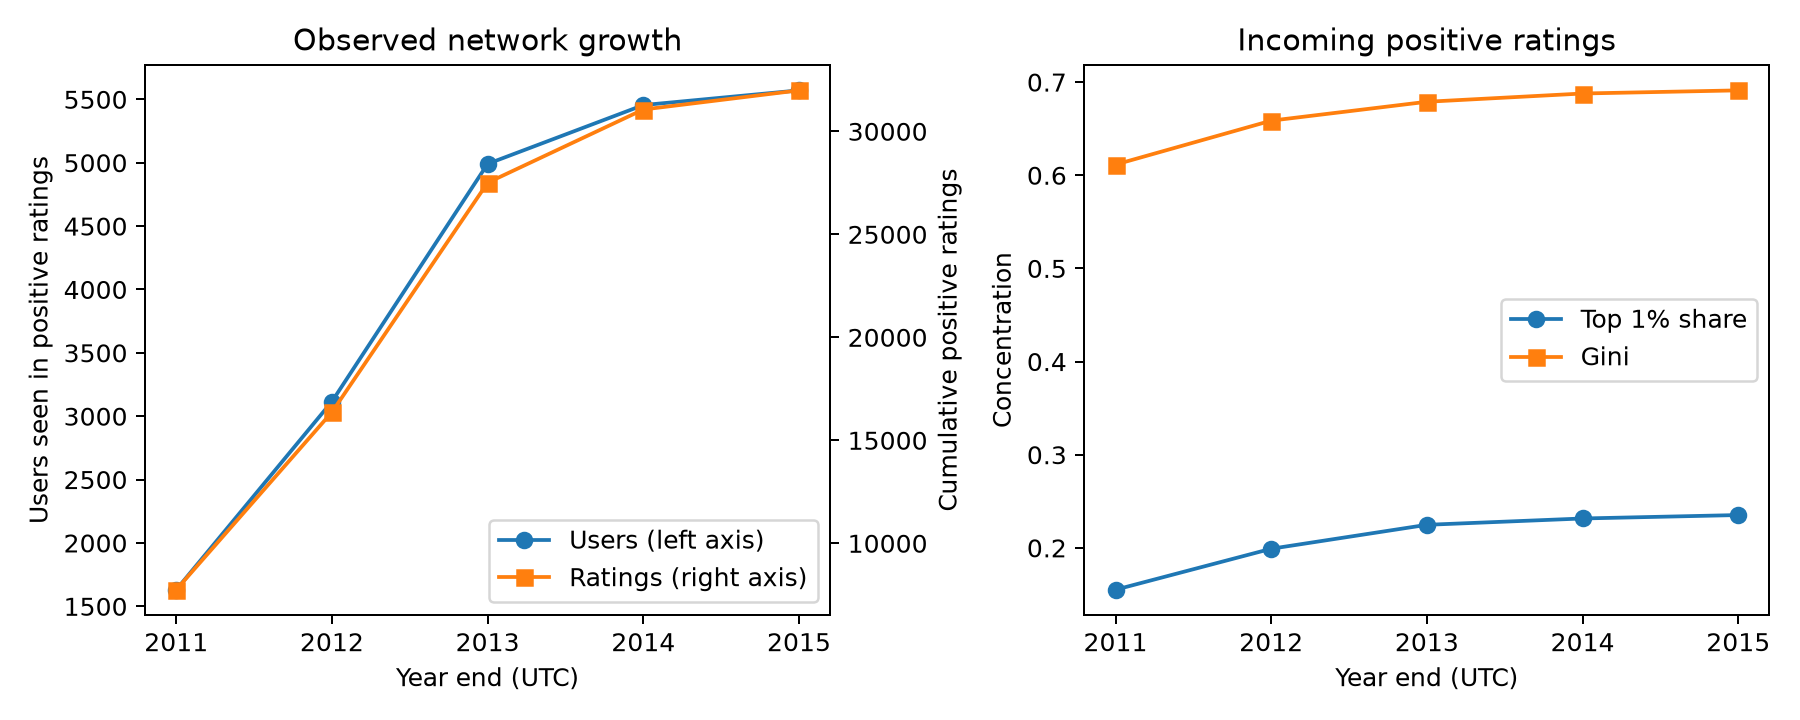

In [2]:
display(annual.round(4))
display(Image(filename=str(OUT / 'growth_and_concentration.png')))

### Recalculate one Bitcoin OTC result from the source

This cell reads the source rows rather than the saved result table. Keep positive ratings recorded by the end of 2015, count incoming ratings for every user observed in those rows, and take the highest-ranked 1%, rounding the number of users upward. This is the same definition used in the annual table.

In [3]:
import numpy as np

source_ratings = pd.read_csv(
    ROOT / 'data' / 'soc-sign-bitcoinotc.csv.gz',
    header=None, names=['source', 'target', 'rating', 'time'],
)
cutoff = pd.Timestamp('2016-01-01', tz='UTC').timestamp()
recorded_2015 = source_ratings[(source_ratings.rating > 0) & (source_ratings.time < cutoff)]
users_2015 = sorted(set(recorded_2015.source) | set(recorded_2015.target))
incoming_2015 = recorded_2015.groupby('target').size().reindex(users_2015, fill_value=0)
top_group_size = int(np.ceil(0.01 * len(users_2015)))
top_share = incoming_2015.nlargest(top_group_size).sum() / incoming_2015.sum()

print('Users observed so far:', len(users_2015))
print('Top group size:', top_group_size)
print('Top 1% incoming share:', round(top_share, 4))
saved_share = annual.set_index('year_end').loc[2015, 'top_1_percent_incoming_share']
assert np.isclose(top_share, saved_share)

Users observed so far: 5571
Top group size: 56
Top 1% incoming share: 0.2352


## 3. Event-level target-choice comparison

Before each positive rating, the candidate set contains users seen in earlier positive ratings, excluding the rater and users the rater previously rated positively. If the actual target is new, that event is excluded from this particular comparison. For each eligible event, we calculate the probability that a uniformly drawn eligible target belongs to each **prior positive in-degree** bin. Summing those probabilities gives the expected count for that bin. A ratio of one means that the observed and expected counts are equal. This conditions on the changing pool of observed users and past positive ratings from the same source, but **does not control for user activity, tenure, trading volume, or platform membership**. A high ratio is an association, not proof of preferential attachment.

,prior_positive_in_degree,observed_target_events,uniform_null_expected_events,observed_over_expected
0,0,601,341.660,1.759
1,1,3090,11200.671,0.276
2,2-3,3717,7671.863,0.484
3,4-7,4145,4133.610,1.003
4,8-15,4223,2282.943,1.850
5,16-31,4001,922.895,4.335
6,32+,7356,579.358,12.697


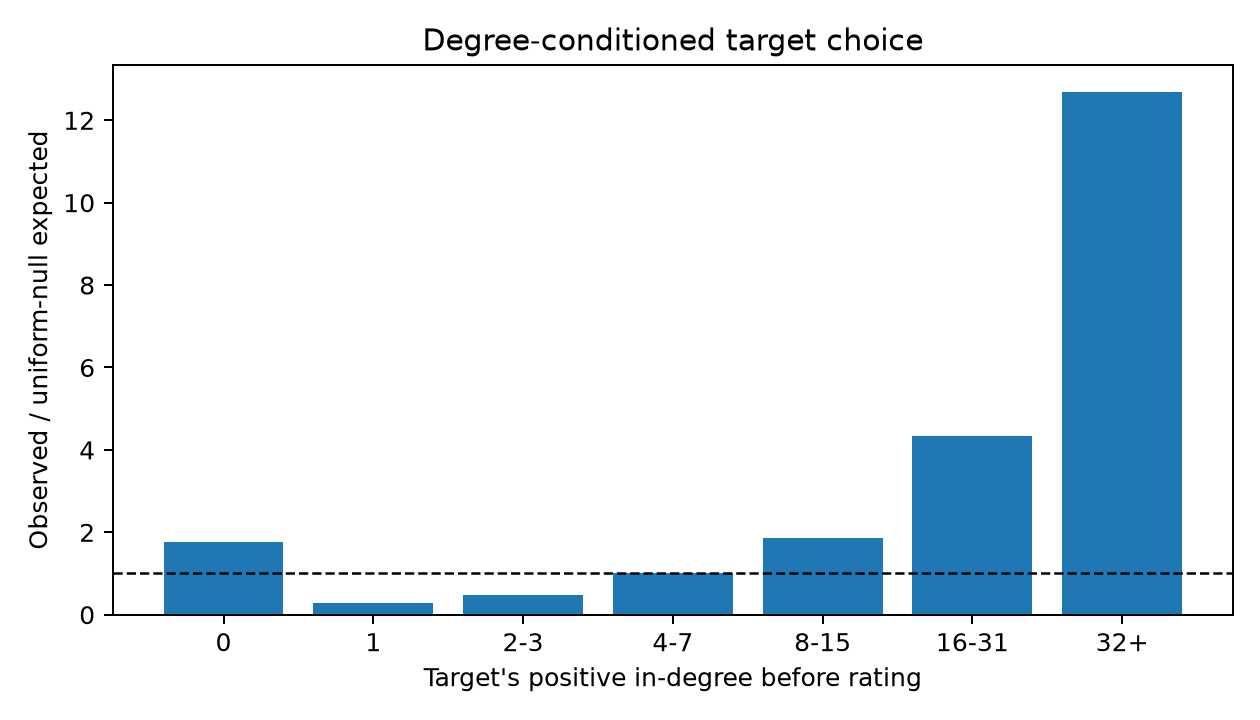

,year,prior_positive_in_degree,observed_target_events,uniform_null_expected_events,observed_over_expected
13,2011,32+,720,63.739,11.296
20,2012,32+,2107,162.001,13.006
27,2013,32+,2942,243.703,12.072
34,2014,32+,1147,86.252,13.298
41,2015,32+,419,22.636,18.510


In [4]:
display(choice.round(3))
display(Image(filename=str(OUT / 'target_choice_ratio.png')))
display(by_year[by_year.prior_positive_in_degree == '32+'].query('2011 <= year <= 2015').round(3))

### Follow the candidate set before one rating

This is an **invented six-event example**, separate from the source data. Before the last event A→C, the known users are A, B, C, D, and E. A already rated B, so A and B are excluded. The eligible recipients are C, D, and E. C has one earlier incoming rating; D and E have none. If these three recipients are equally likely, the probability of selecting the prior-degree-one group is $1/3$.

In [5]:
example_events = pd.DataFrame([
    ('A', 'B'), ('B', 'C'), ('C', 'B'),
    ('D', 'A'), ('E', 'A'), ('A', 'C'),
], columns=['source', 'target'])
history = example_events.iloc[:-1]  # use only events BEFORE the last rating
source, target = example_events.iloc[-1]
seen = set(history.source) | set(history.target)
already_rated = set(history.loc[history.source == source, 'target'])
eligible = sorted(seen - {source} - already_rated)
prior_incoming = history.groupby('target').size()
candidate_table = pd.DataFrame({
    'candidate': eligible,
    'prior_positive_in_degree': [int(prior_incoming.get(user, 0)) for user in eligible],
})
display(example_events)
display(candidate_table)

observed_degree_one = int(prior_incoming.get(target, 0) == 1)
expected_degree_one = (candidate_table.prior_positive_in_degree == 1).mean()
print('Observed degree-one selection:', observed_degree_one)
print('Uniform expected degree-one selection:', expected_degree_one)
print('Observed / expected for this event:', observed_degree_one / expected_degree_one)
assert target in eligible
assert np.isclose(expected_degree_one, 1 / 3)

,source,target
0,A,B
1,B,C
2,C,B
3,D,A
4,E,A
5,A,C


,candidate,prior_positive_in_degree
0,C,1
1,D,0
2,E,0


Observed degree-one selection: 1
Uniform expected degree-one selection: 0.3333333333333333
Observed / expected for this event: 3.0


For this single event the ratio is $1/(1/3)=3$. One event does not establish a pattern. The full script **sums observed counts and expected probabilities over events first**, then divides the two totals for each degree group. It does not average event ratios. If the actual recipient has never appeared before, the event is excluded from this existing-recipient comparison. Notebook 04 narrows the eligible set by observed tenure and recent activity.

## 4. Sensitivity and interpretation

The cumulative year-end concentration is recomputed with ratings of at least +5. This threshold is a sensitivity choice, not a new definition of true trust. The cumulative positive-rating record became more concentrated among users observed so far. The annual-only comparison below rises to 2013 and then falls, so the cumulative finding does not establish steadily increasing concentration in new ratings. High-prior-degree users were overrepresented relative to a uniform eligible-target benchmark. The dataset lacks verified transactions and unobserved nonrating platform users. Because there are no repeated directed pairs, it also cannot show how a user's rating of the same person changed.

In [6]:
display(strong.round(4))
print('Top 1% incoming share, 2011 to 2015:')
print('All positive:', round(annual.iloc[0].top_1_percent_incoming_share, 3), 'to', round(annual.iloc[-1].top_1_percent_incoming_share, 3))
print('Rating >=5:', round(strong.iloc[0].top_1_percent_incoming_share, 3), 'to', round(strong.iloc[-1].top_1_percent_incoming_share, 3))

,rating_threshold,year_end,active_positive_users,cumulative_positive_ratings,top_1_percent_incoming_share,incoming_degree_gini,top_group_size
0,5,2011,443,643,0.1633,0.5502,5
1,5,2012,850,1429,0.1659,0.6216,9
2,5,2013,1398,2451,0.1877,0.6614,14
3,5,2014,1551,2793,0.1926,0.6660,16
4,5,2015,1585,2885,0.1931,0.6694,16


Top 1% incoming share, 2011 to 2015:
All positive: 0.155 to 0.235
Rating >=5: 0.163 to 0.193


## 5. Separate accumulated ratings from new yearly ratings

A cumulative total remembers every earlier rating. It can become more concentrated even when **new ratings in the latest years** are less concentrated. `scripts/temporal_sensitivity.py` therefore counts each calendar year's positive ratings separately. Its users are those appearing as a source or recipient **in that year's positive records**. A changing annual user population and falling rating volume also affect this comparison.

,year,users_in_denominator,incoming_ratings_in_denominator,top_group_size,top_1_percent_incoming_share,incoming_degree_gini
0,2011,1618,7603,17,0.1527,0.6083
1,2012,1823,8622,19,0.1967,0.6568
2,2013,2480,11138,25,0.2096,0.6490
3,2014,916,3555,10,0.1437,0.6256
4,2015,323,929,4,0.1130,0.5728


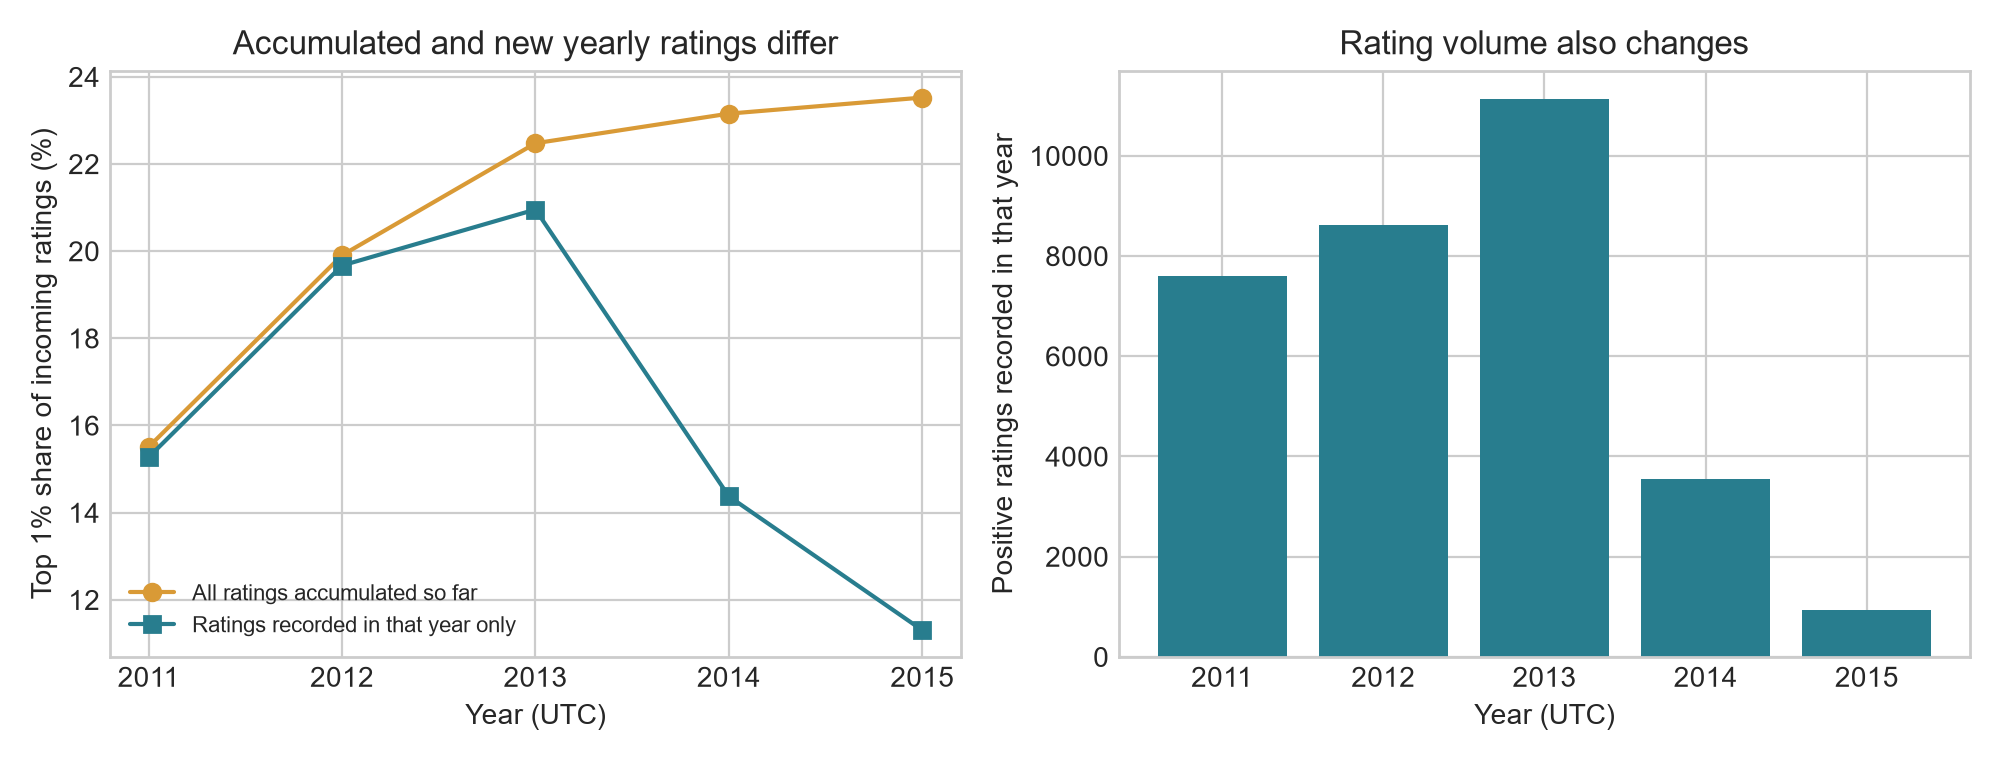

2015 only: 929 ratings among 323 users
Top group size: 4 ; incoming share: 0.113


In [7]:
SENSITIVITY = ROOT / 'outputs' / 'sensitivity'
annual_only = pd.read_csv(SENSITIVITY / 'annual_only_concentration.csv')
fixed_cohort = pd.read_csv(SENSITIVITY / 'fixed_2011_cohort_concentration.csv')
display(annual_only.round(4))
display(Image(filename=str(SENSITIVITY / 'annual_vs_cumulative_concentration.png')))

# Recalculate the 2015 annual-only share directly from the original rows.
start_2015 = pd.Timestamp('2015-01-01', tz='UTC').timestamp()
yearly_positive = source_ratings[
    (source_ratings.rating > 0)
    & (source_ratings.time >= start_2015)
    & (source_ratings.time < cutoff)
]
yearly_users = sorted(set(yearly_positive.source) | set(yearly_positive.target))
yearly_incoming = yearly_positive.groupby('target').size().reindex(yearly_users, fill_value=0)
yearly_top_count = int(np.ceil(0.01 * len(yearly_users)))
yearly_top_share = yearly_incoming.nlargest(yearly_top_count).sum() / yearly_incoming.sum()
print('2015 only:', len(yearly_positive), 'ratings among', len(yearly_users), 'users')
print('Top group size:', yearly_top_count, '; incoming share:', round(yearly_top_share, 4))
assert np.isclose(yearly_top_share, annual_only.set_index('year').loc[2015, 'top_1_percent_incoming_share'])

Annual-only concentration rises to 2013 and then falls; the cumulative series rises throughout the five snapshots. These results answer different questions. We can describe concentration in the accumulated record, but cannot claim that new ratings became steadily more concentrated every year.

The fixed-cohort check keeps the **same 1,631 users observed by the end of 2011** in every denominator. It counts all cumulative positive ratings received by those users, including ratings given by later entrants. Within that fixed group, top-1% concentration also rises. This shows that the cumulative increase does not arise solely from adding new users to the denominator. The cohort was selected early, so it does not represent later entrants, and its rating denominator contains only ratings received by cohort members.

**Check the fall at equal volume.** The top 1% contains 25 users in 2013 but only 4 in 2015, and there are far fewer ratings, so the raw shares are not directly comparable. The next cell redraws every year to the same number of ratings. At equal volume, the 2013 and 2015 shares have overlapping ranges, and the share held by a fixed number of recipients rises. Most of the apparent fall is therefore a volume effect.

In [8]:
display(pd.read_csv(SENSITIVITY / 'annual_equal_volume_check.csv').round(4))

,year,ratings,top_1_percent_share,equal_volume_ratings,equal_volume_share_mean,equal_volume_share_low,equal_volume_share_high,fixed_recipients,fixed_recipients_share,fixed_recipients_equal_volume_mean,fixed_recipients_equal_volume_low,fixed_recipients_equal_volume_high
0,2011,7603,0.1527,743,0.0954,0.0794,0.1117,4,0.0583,0.0642,0.0498,0.0781
1,2012,8622,0.1967,743,0.1121,0.0929,0.1332,4,0.0699,0.0748,0.0592,0.0915
2,2013,11138,0.2096,743,0.1205,0.1009,0.1413,4,0.0729,0.0778,0.0619,0.0956
3,2014,3555,0.1437,743,0.0961,0.0794,0.1157,4,0.0731,0.0786,0.0646,0.0942
4,2015,929,0.1130,743,0.0996,0.0834,0.1225,4,0.1130,0.1156,0.1063,0.1252


,year_end,users_in_denominator,incoming_ratings_in_denominator,top_group_size,top_1_percent_incoming_share,incoming_degree_gini,share_of_all_cumulative_ratings_received_by_cohort
0,2011,1631,7745,17,0.1551,0.6115,1.0000
1,2012,1631,10526,17,0.1881,0.6698,0.6431
2,2013,1631,12090,17,0.2143,0.6950,0.4396
3,2014,1631,12587,17,0.2196,0.7028,0.4052
4,2015,1631,12739,17,0.2218,0.7054,0.3982


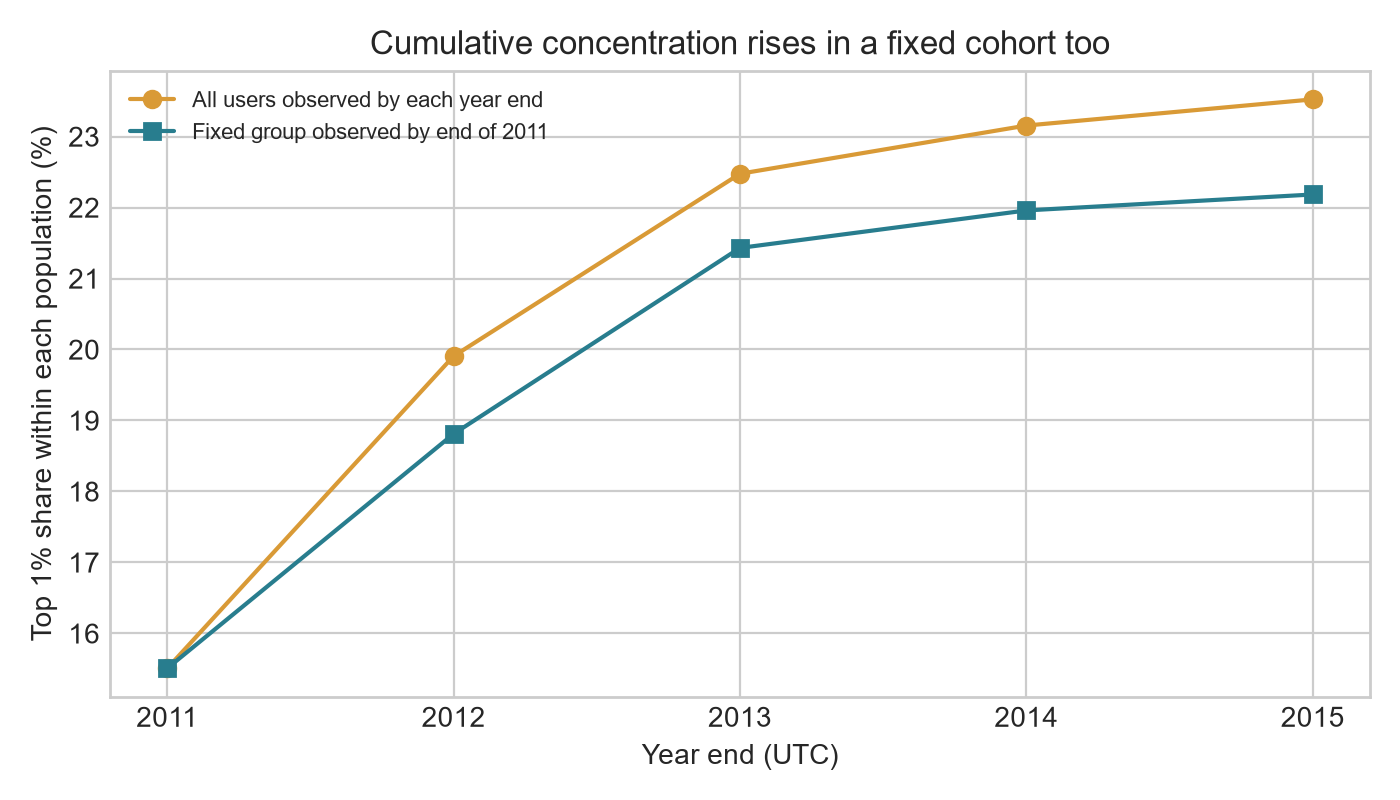

In [9]:
display(fixed_cohort.round(4))
display(Image(filename=str(SENSITIVITY / 'fixed_cohort_concentration.png')))
assert fixed_cohort.users_in_denominator.nunique() == 1

## References

- [SNAP Bitcoin OTC dataset and original dataset paper](https://snap.stanford.edu/data/soc-sign-bitcoinotc.html)
- [Barabási and Albert (1999), emergence of scaling](https://doi.org/10.1126/science.286.5439.509)
- [Jeong, Néda, and Barabási (2003), measuring preferential attachment](https://doi.org/10.1209/epl/i2003-00166-9)

The analysis borrows the idea of measuring new links against prior degree, but its null model and observational limits are stated explicitly above.